In [76]:
from typing import List, Callable
from scipy.optimize import approx_fprime, minimize
from scipy.differentiate import hessian

import matplotlib.pyplot as plt
import numpy as np
from timeit import timeit

import sys
sys.path.insert(0, "../")
from visualisation import plot_trajectory_3d_plotly, plot_trajectory
from test_functions import rosenbroke, himmelbau, rostrigin, izom

Vector = List[float]

In [77]:
def function(x: Vector): return 4*x[0]**2 + 4*x[0] + x[1]**2 - 8*x[1] + 5

def condition(x: Vector): return 2*x[0] - x[1] - 6

def penalty_func(x: List[float], func: Callable, r: float, cond: List[Callable]) -> float:
    penalty = 0.0
    
    for g in cond:
        penalty += g(x)**2
        
    return func(x) + (r / 2.0) * penalty

In [96]:
def fine_method(x: Vector, function: Callable, cond:Callable, C = 10.0, eps = 1e-8, r0 = 1.0, max_iter = 1000):
    x_k = np.array(x, dtype=float)
    k = 0
    r_k = r0
    traj = [x.copy()]
    
    # print(f"Старт {x_k}, f(x) = {function(x_k)}")
    
    while k <= max_iter:
        function_to_minimize = lambda x: penalty_func(x, function, r_k, cond)
        
        res = minimize(function_to_minimize, x_k, method="BFGS")
        x_new = res.x
        traj.append(x_new.copy())
        
        diff = np.linalg.norm(x_new - x_k)
        
        if diff <= eps:
            # print("Дело сделано")
            break
            
        x_k = x_new
        r_k *= C
        
        k+=1
        
    return x_k, function(x_k), k-1, traj

In [97]:
%timeit fine_method([10, -10], function, [condition], eps=1e-12)

49.4 ms ± 1.58 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [94]:
x_func,f_func, k_func, traj_func = fine_method([10, -10], function, [condition], eps=1e-12)

Старт [ 10. -10.], f(x) = 625.0
Дело сделано


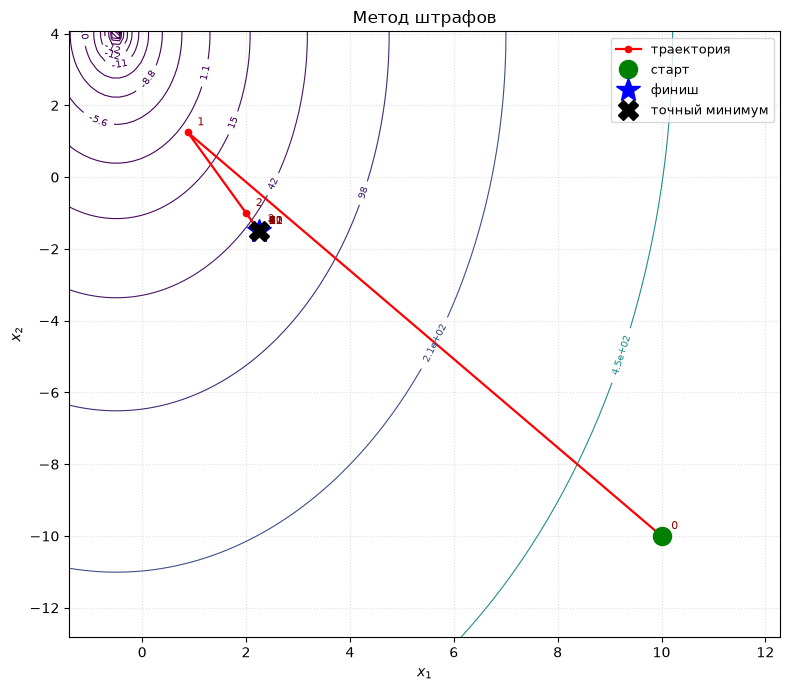

In [91]:
plot_trajectory(function, traj_func, title='Метод штрафов', exact=(2.25, -1.5))

In [92]:
plot_trajectory_3d_plotly(function, traj_func, title='Метод штрафов', exact=(2.25, -1.5))